# Assignment 7 — Transfer Learning with Pre-trained CNN Models

**Objective:** Implement transfer learning using pre-trained **AlexNet, VGG16, ResNet50, and EfficientNet-B0** for image classification and compare their performance.

### Standalone setup
- Dataset: **CIFAR-10** (built into `torchvision`)
- Framework: **PyTorch + Torchvision**
- Pre-trained weights: **ImageNet**
- Transfer-learning strategy: freeze the pre-trained feature extractor and train only the final classification layer
- The same train/test split, preprocessing, optimizer, epochs, and batch size are used for all four models.

## 1. Install Required Libraries

Run this cell once if the packages are not already installed.

In [1]:
%pip install -q torch torchvision scikit-learn matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Libraries and Check Hardware

In [6]:
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch version:', torch.__version__)
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch version: 2.14.0+cpu
Device: cpu


## 3. Define Dataset and Image Preprocessing

CIFAR-10 images are 32×32 RGB images. ImageNet-pretrained models expect larger images, so they are resized to 224×224. ImageNet normalization is used because the pretrained weights were learned with this normalization.

In [7]:
DATA_DIR = './data'
IMAGE_SIZE = 224
BATCH_SIZE = 64
NUM_CLASSES = 10
EPOCHS = 3

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=test_transform
)

class_names = train_dataset.classes
print('Classes:', class_names)
print('Training images:', len(train_dataset))
print('Testing images:', len(test_dataset))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Testing images: 10000


## 4. Optional Fast-Run Mode

For a college demonstration on a CPU, set `USE_SUBSET = True`. For the full experiment, set it to `False`. A GPU is strongly recommended for training all four models.

In [8]:
USE_SUBSET = True
TRAIN_SAMPLES = 10000
TEST_SAMPLES = 2000

if USE_SUBSET:
    train_indices = np.random.RandomState(42).choice(len(train_dataset), TRAIN_SAMPLES, replace=False)
    test_indices = np.random.RandomState(42).choice(len(test_dataset), TEST_SAMPLES, replace=False)
    train_data = Subset(train_dataset, train_indices)
    test_data = Subset(test_dataset, test_indices)
else:
    train_data = train_dataset
    test_data = test_dataset

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

print('Experiment training images:', len(train_data))
print('Experiment testing images:', len(test_data))

Experiment training images: 10000
Experiment testing images: 2000


## 5. Visualize Sample Images

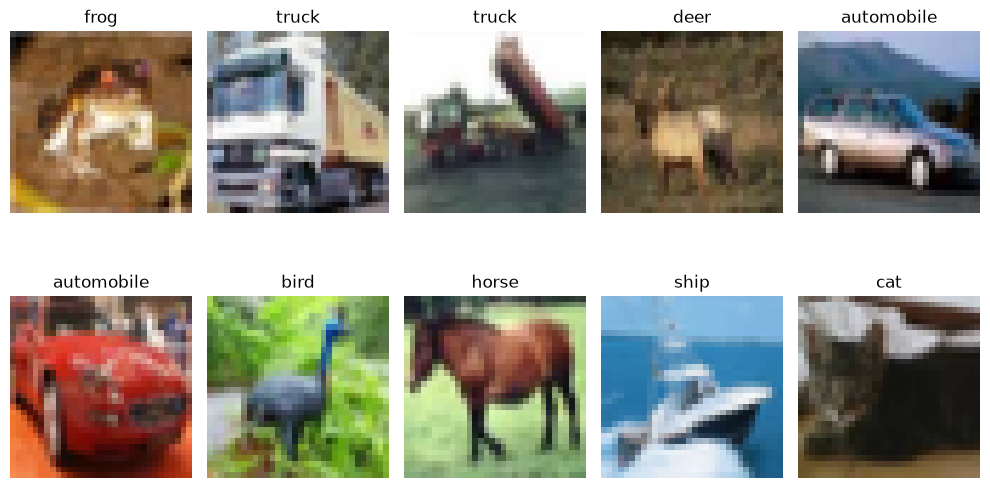

In [9]:
raw_dataset = datasets.CIFAR10(root=DATA_DIR, train=True, download=False)

plt.figure(figsize=(10, 6))
for i in range(10):
    image, label = raw_dataset[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_names[label])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 6. Build the Four Transfer-Learning Models

**Important:** AlexNet is not part of `torchvision.models`' TensorFlow/Keras-style applications list, but it is available in `torchvision` with ImageNet-pretrained weights. This notebook therefore uses PyTorch/Torchvision consistently for all four required architectures.

In [10]:
def freeze_all(model):
    for param in model.parameters():
        param.requires_grad = False


def create_alexnet():
    model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
    freeze_all(model)
    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Linear(in_features, NUM_CLASSES)
    return model


def create_vgg16():
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    freeze_all(model)
    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Linear(in_features, NUM_CLASSES)
    return model


def create_resnet50():
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    freeze_all(model)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, NUM_CLASSES)
    return model


def create_efficientnetb0():
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    freeze_all(model)
    in_features = model.classifier[-1].in_features
    model.classifier[-1] = nn.Linear(in_features, NUM_CLASSES)
    return model


model_builders = {
    'AlexNet': create_alexnet,
    'VGG16': create_vgg16,
    'ResNet50': create_resnet50,
    'EfficientNetB0': create_efficientnetb0
}

print('Models configured:', ', '.join(model_builders.keys()))

Models configured: AlexNet, VGG16, ResNet50, EfficientNetB0


## 7. Training and Evaluation Functions

In [11]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)

    avg_loss = running_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
    f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

    return avg_loss, accuracy, precision, recall, f1, all_labels, all_predictions


def run_experiment(name, builder, epochs=EPOCHS):
    print('\n' + '=' * 70)
    print(f'Training {name}')
    print('=' * 70)

    model = builder().to(device)
    criterion = nn.CrossEntropyLoss()
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(trainable_params, lr=0.001)

    history = {'train_loss': [], 'train_accuracy': [], 'test_loss': [], 'test_accuracy': []}
    start_time = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        test_loss, test_acc, _, _, _, _, _ = evaluate(model, test_loader, criterion)

        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_accuracy'].append(test_acc)

        print(
            f'Epoch {epoch + 1}/{epochs} | '
            f'Train Loss: {train_loss:.4f} | '
            f'Train Acc: {train_acc * 100:.2f}% | '
            f'Test Acc: {test_acc * 100:.2f}%'
        )

    elapsed = time.time() - start_time
    final_metrics = evaluate(model, test_loader, criterion)

    result = {
        'Model': name,
        'Accuracy': final_metrics[1],
        'Precision': final_metrics[2],
        'Recall': final_metrics[3],
        'F1-Score': final_metrics[4],
        'Training Time (sec)': elapsed,
        'History': history,
        'Labels': final_metrics[5],
        'Predictions': final_metrics[6]
    }

    return model, result

## 8. Train and Evaluate AlexNet

In [12]:
alexnet_model, alexnet_result = run_experiment('AlexNet', create_alexnet)


Training AlexNet
Epoch 1/3 | Train Loss: 0.8582 | Train Acc: 69.24% | Test Acc: 75.70%
Epoch 2/3 | Train Loss: 0.6340 | Train Acc: 77.68% | Test Acc: 78.20%
Epoch 3/3 | Train Loss: 0.5663 | Train Acc: 79.97% | Test Acc: 78.55%


## 9. Train and Evaluate VGG16

In [13]:
vgg16_model, vgg16_result = run_experiment('VGG16', create_vgg16)


Training VGG16
Epoch 1/3 | Train Loss: 0.7830 | Train Acc: 73.07% | Test Acc: 78.85%
Epoch 2/3 | Train Loss: 0.5895 | Train Acc: 79.35% | Test Acc: 80.20%
Epoch 3/3 | Train Loss: 0.5535 | Train Acc: 80.55% | Test Acc: 80.40%


## 10. Train and Evaluate ResNet50

In [14]:
resnet50_model, resnet50_result = run_experiment('ResNet50', create_resnet50)


Training ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\manth/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%


Epoch 1/3 | Train Loss: 1.2656 | Train Acc: 63.50% | Test Acc: 72.20%
Epoch 2/3 | Train Loss: 0.8108 | Train Acc: 74.84% | Test Acc: 75.20%
Epoch 3/3 | Train Loss: 0.7017 | Train Acc: 77.36% | Test Acc: 75.95%


## 11. Train and Evaluate EfficientNet-B0

In [15]:
efficientnet_model, efficientnet_result = run_experiment('EfficientNetB0', create_efficientnetb0)


Training EfficientNetB0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\manth/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100.0%


Epoch 1/3 | Train Loss: 1.3198 | Train Acc: 63.31% | Test Acc: 73.35%
Epoch 2/3 | Train Loss: 0.8587 | Train Acc: 73.56% | Test Acc: 76.80%
Epoch 3/3 | Train Loss: 0.7603 | Train Acc: 75.63% | Test Acc: 77.00%


## 12. Compare Model Performance

In [16]:
results = [alexnet_result, vgg16_result, resnet50_result, efficientnet_result]

comparison = pd.DataFrame([
    {
        'Model': r['Model'],
        'Accuracy': r['Accuracy'],
        'Precision': r['Precision'],
        'Recall': r['Recall'],
        'F1-Score': r['F1-Score'],
        'Training Time (sec)': r['Training Time (sec)']
    }
    for r in results
])

display(comparison.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Training Time (sec)': '{:.2f}'
}))

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (sec)
0,AlexNet,0.7855,0.7910,0.7855,0.7842,147.43
1,VGG16,0.8040,0.8061,0.8040,0.8032,2640.35
2,ResNet50,0.7595,0.7673,0.7595,0.7604,1429.01
3,EfficientNetB0,0.7700,0.7713,0.7700,0.7697,655.43


## 13. Plot Accuracy Comparison

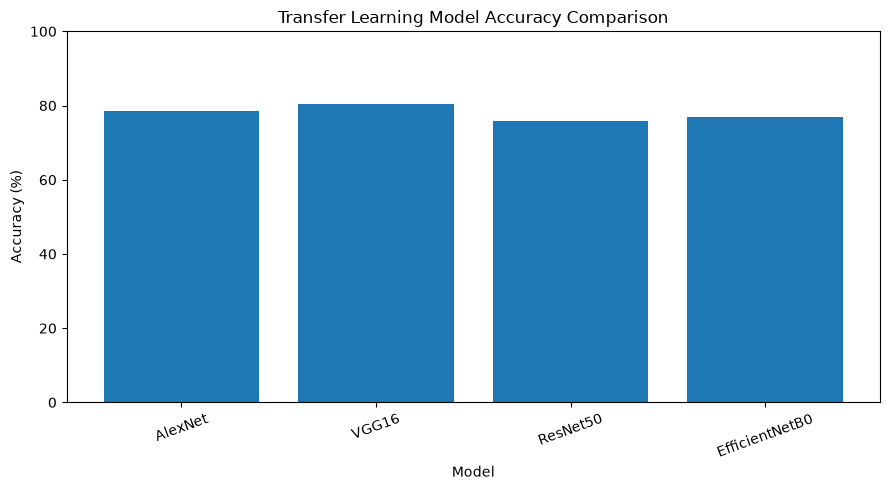

In [17]:
plt.figure(figsize=(9, 5))
plt.bar(comparison['Model'], comparison['Accuracy'] * 100)
plt.ylabel('Accuracy (%)')
plt.xlabel('Model')
plt.title('Transfer Learning Model Accuracy Comparison')
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 14. Compare Precision, Recall and F1-Score

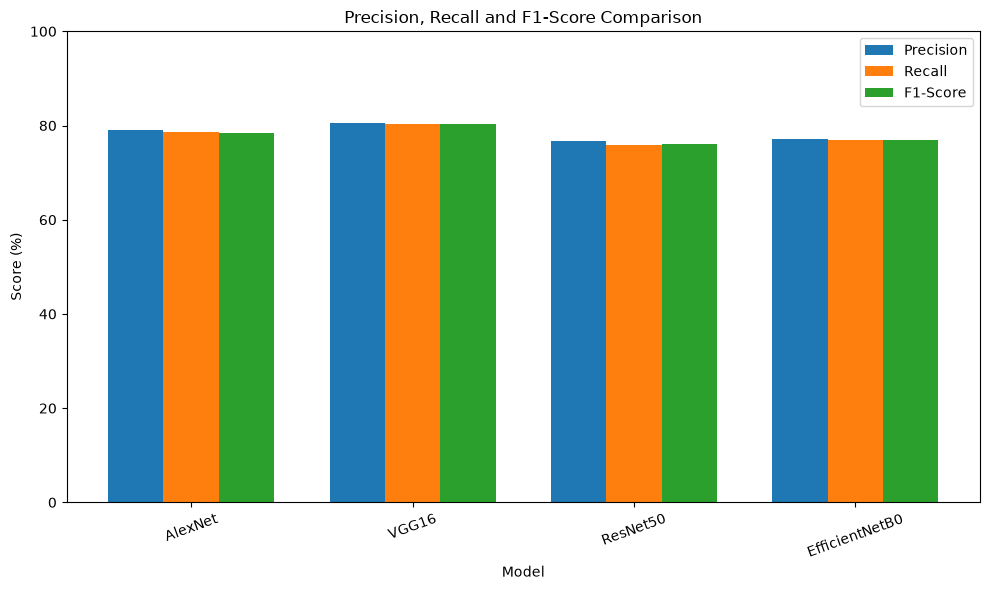

In [18]:
metrics = ['Precision', 'Recall', 'F1-Score']
x = np.arange(len(comparison['Model']))
width = 0.25

plt.figure(figsize=(10, 6))
for i, metric in enumerate(metrics):
    plt.bar(x + (i - 1) * width, comparison[metric] * 100, width, label=metric)

plt.xticks(x, comparison['Model'], rotation=20)
plt.ylabel('Score (%)')
plt.xlabel('Model')
plt.title('Precision, Recall and F1-Score Comparison')
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

## 15. Training Curves

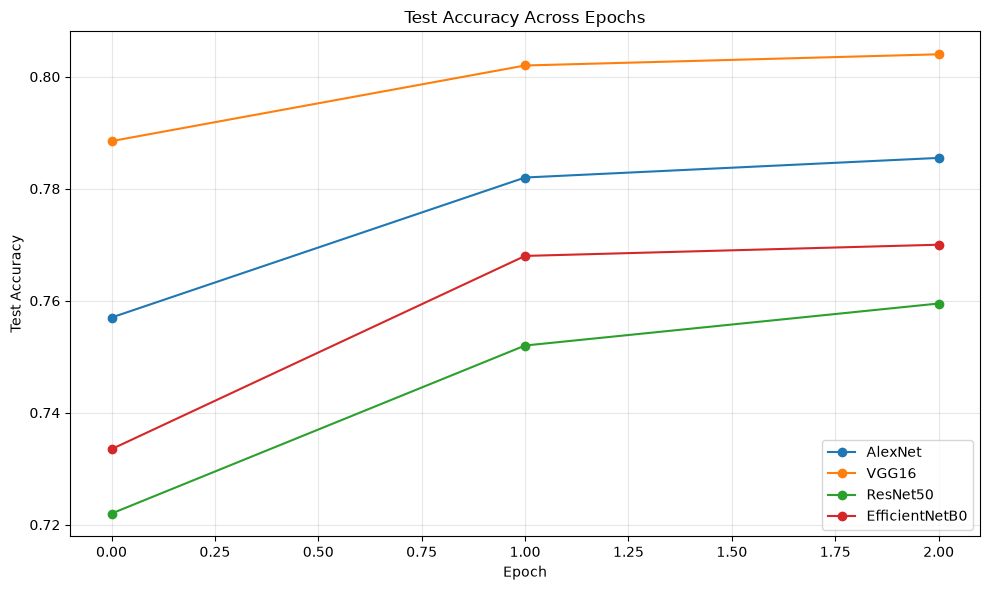

In [19]:
plt.figure(figsize=(10, 6))

for result in results:
    plt.plot(
        result['History']['test_accuracy'],
        marker='o',
        label=result['Model']
    )

plt.xlabel('Epoch')
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy Across Epochs')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Confusion Matrix for Each Model

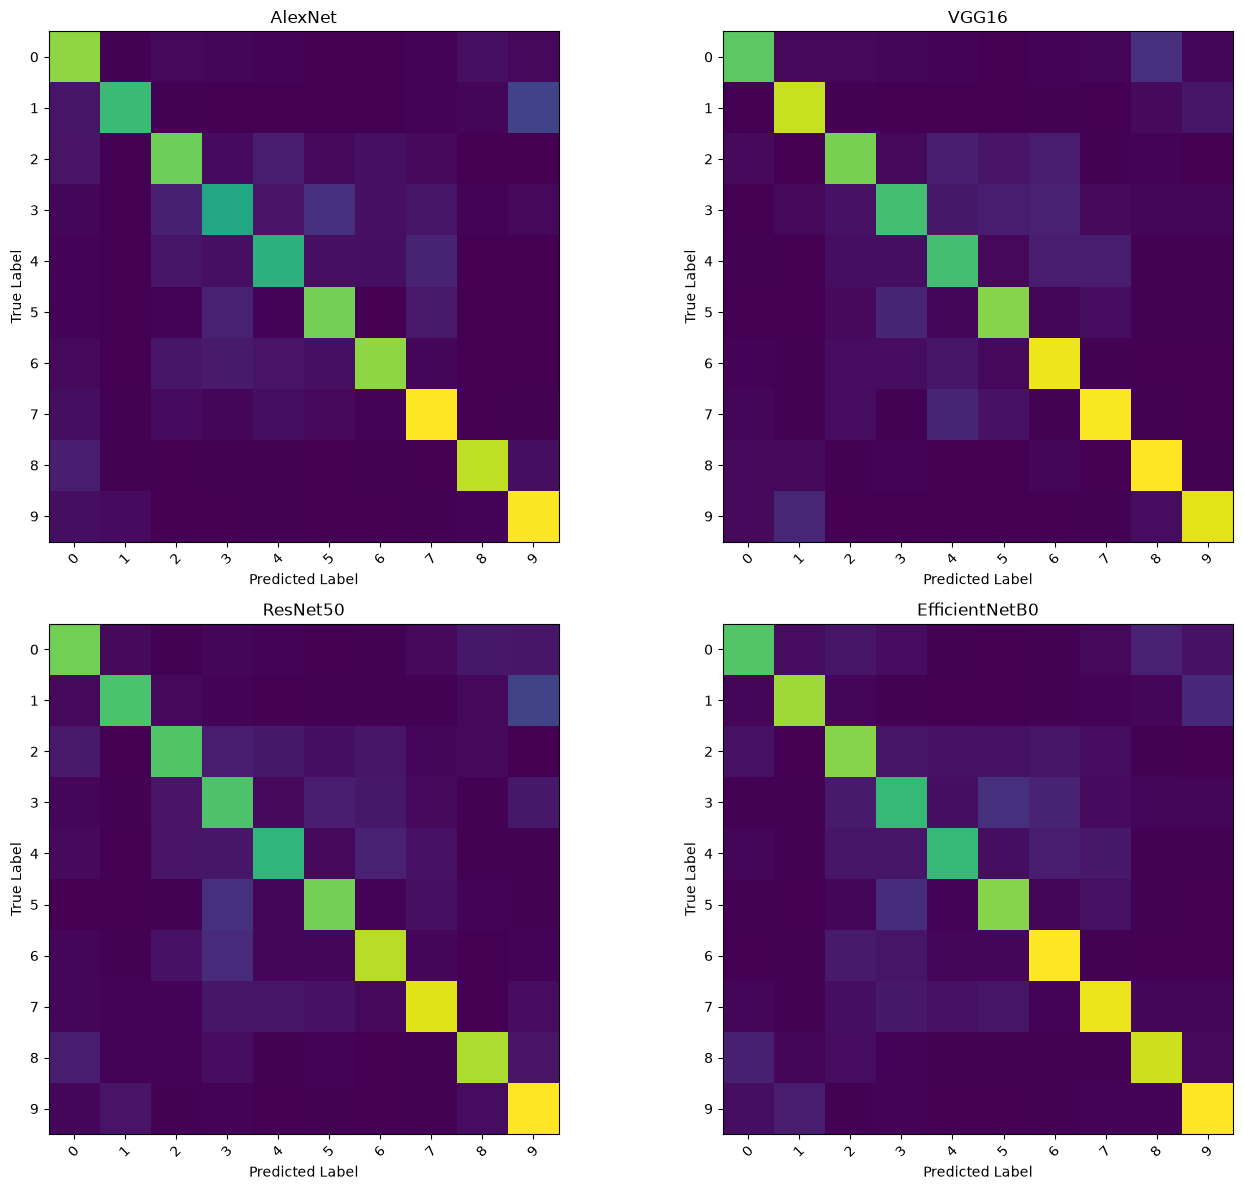

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, result in zip(axes.ravel(), results):
    cm = confusion_matrix(result['Labels'], result['Predictions'])
    ax.imshow(cm)
    ax.set_title(result['Model'])
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(range(NUM_CLASSES), rotation=45)
    ax.set_yticklabels(range(NUM_CLASSES))

plt.tight_layout()
plt.show()

## 17. Detailed Classification Report

The following cell prints precision, recall and F1-score for every CIFAR-10 class.

In [21]:
for result in results:
    print('\n' + '=' * 70)
    print(result['Model'])
    print('=' * 70)
    print(classification_report(
        result['Labels'],
        result['Predictions'],
        target_names=class_names,
        zero_division=0
    ))


AlexNet
              precision    recall  f1-score   support

    airplane       0.72      0.87      0.79       187
  automobile       0.94      0.70      0.80       189
        bird       0.74      0.76      0.75       201
         cat       0.69      0.59      0.64       198
        deer       0.72      0.69      0.71       181
         dog       0.75      0.81      0.78       191
        frog       0.86      0.76      0.81       213
       horse       0.78      0.86      0.82       226
        ship       0.92      0.87      0.89       203
       truck       0.78      0.92      0.84       211

    accuracy                           0.79      2000
   macro avg       0.79      0.78      0.78      2000
weighted avg       0.79      0.79      0.78      2000


VGG16
              precision    recall  f1-score   support

    airplane       0.87      0.75      0.80       187
  automobile       0.83      0.90      0.87       189
        bird       0.79      0.74      0.77       201
        

## 18. Save the Trained Models

The models are saved as PyTorch state dictionaries containing the trained weights.

In [22]:
torch.save(alexnet_model.state_dict(), 'alexnet_transfer_learning.pth')
torch.save(vgg16_model.state_dict(), 'vgg16_transfer_learning.pth')
torch.save(resnet50_model.state_dict(), 'resnet50_transfer_learning.pth')
torch.save(efficientnet_model.state_dict(), 'efficientnetb0_transfer_learning.pth')

print('All four trained model weights were saved successfully.')

All four trained model weights were saved successfully.


## 19. Conclusion Template

The experiment demonstrates transfer learning by reusing ImageNet-pretrained feature extractors and replacing the original 1000-class classifier with a 10-class CIFAR-10 classifier. Accuracy, precision, recall, F1-score, training time, learning curves, and confusion matrices are used to compare the models.